# Chapitre 18 - Problèmes en grande dimension ($p \gg N$)
## Cours 1 : pourquoi $p \gg N$ est difficile, LDA diagonale et centroïdes réduits

Ce chapitre traite des problèmes de prédiction où le nombre de variables $p$ est
**beaucoup plus grand** que le nombre d'observations $N$. C'est la situation typique
de la génomique : quelques dizaines de patients, des milliers de gènes mesurés.

Dans ce premier notebook :

1. une simulation (figure 18.1 du livre) qui montre que, lorsque $p \gg N$,
   **« moins ajuster, c'est mieux »** : il faut régulariser fortement ;
2. l'**analyse discriminante linéaire diagonale** (règle « d'indépendance ») ;
3. les **centroïdes réduits** (*nearest shrunken centroids*, NSC), appliqués aux
   données de micro-puces NCI (analogue de la figure 18.4).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl import ch18_grande_dimension as g

## 1. Notations et rappels

On dispose de $N$ observations $(x_i, y_i)$, avec $x_i \in \mathbb{R}^p$, rangées dans
la matrice $\mathbf{X}$ de taille $N \times p$ (une ligne par observation).

Lorsque $p > N$, la matrice $\mathbf{X}^T\mathbf{X}$ (de taille $p\times p$) est de rang
au plus $N < p$ : elle est **singulière**. Les moindres carrés ordinaires
$\hat\beta = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T y$ ne sont donc pas définis, et
il existe une infinité de vecteurs $\beta$ qui interpolent exactement les données
(voir l'exercice 18.7).

**Rappel : la régression ridge** (section 3.4.1 du livre). Pour $\lambda > 0$, on
minimise $\|y - \mathbf{X}\beta\|^2 + \lambda\|\beta\|^2$, dont la solution est
$$\hat\beta_\lambda = (\mathbf{X}^T\mathbf{X} + \lambda I_p)^{-1}\mathbf{X}^T y .$$
La matrice $\mathbf{X}^T\mathbf{X} + \lambda I_p$ est inversible car elle est symétrique
et ses valeurs propres sont $\geq \lambda > 0$.

Si $\mathbf{X} = \mathbf{U}\mathbf{D}\mathbf{V}^T$ est la SVD (valeurs singulières
$d_1 \ge \dots \ge d_r$), les **degrés de liberté effectifs** (éq. (3.50) du livre) valent
$$\mathrm{df}(\lambda) = \operatorname{tr}\!\big[\mathbf{X}(\mathbf{X}^T\mathbf{X}+\lambda I)^{-1}\mathbf{X}^T\big]
  = \sum_{j=1}^{r} \frac{d_j^2}{d_j^2+\lambda}.$$
Ils décroissent de $r = \operatorname{rang}(\mathbf{X})$ (pour $\lambda \to 0$) à $0$
(pour $\lambda\to\infty$) : c'est une mesure plus parlante que $\lambda$ de la
complexité de l'ajustement.

## 2. Une simulation : « moins ajuster, c'est mieux » (figure 18.1)

**Protocole** (reformulé d'après la section 18.1) :

- $N = 100$ observations, $p \in \{20, 100, 1000\}$ variables gaussiennes centrées
  réduites, de **corrélation deux à deux $0.2$** ;
- $Y = \sum_{j} X_j\beta_j + \sigma\varepsilon$ (éq. (18.1)), avec
  $\varepsilon \sim \mathcal N(0,1)$ et des coefficients $\beta_j \sim \mathcal N(0,1)$
  tirés à nouveau pour chaque jeu de données ;
- $\sigma$ est choisi pour que le **rapport signal sur bruit**
  $\operatorname{Var}[\mathbb E(Y\mid X)]/\sigma^2$ vaille $2$ ;
- on ajuste une ridge avec $\lambda \in \{0.001,\ 100,\ 1000\}$.

**Construire des variables de corrélation 0.2.** Soient $Z_1,\dots,Z_p$ et $W$
indépendantes $\mathcal N(0,1)$, et $X_j = \sqrt{0.8}\,Z_j + \sqrt{0.2}\,W$. Alors,
par indépendance,
$$\operatorname{Var}(X_j) = 0.8 + 0.2 = 1, \qquad
  \operatorname{Cov}(X_j, X_k) = \operatorname{Cov}(\sqrt{0.2}W, \sqrt{0.2}W) = 0.2 \quad (j\neq k).$$
La matrice de covariance est donc $\Sigma = 0.8\, I_p + 0.2\, \mathbf 1\mathbf 1^T$.

**Erreur de test exacte.** Pour un nouveau point $(x_0, Y_0)$ indépendant de
l'échantillon d'apprentissage, avec $Y_0 = x_0^T\beta + \sigma\varepsilon_0$ et
$x_0 \sim \mathcal N(0, \Sigma)$, on a, conditionnellement à $\hat\beta$ :
$$\begin{aligned}
\mathbb E\big[(Y_0 - x_0^T\hat\beta)^2\big]
  &= \mathbb E\big[(\sigma\varepsilon_0 - x_0^T(\hat\beta - \beta))^2\big] \\
  &= \sigma^2 + \mathbb E\big[(x_0^T e)^2\big] \qquad (e = \hat\beta-\beta,\ \text{le terme croisé est nul car } \varepsilon_0 \perp x_0 \text{ et } \mathbb E\varepsilon_0 = 0)\\
  &= \sigma^2 + e^T\,\mathbb E[x_0x_0^T]\,e = \sigma^2 + e^T\Sigma e .
\end{aligned}$$
L'**erreur relative** (erreur de test divisée par l'erreur de Bayes $\sigma^2$) vaut
donc $1 + e^T\Sigma e/\sigma^2$ ; pas besoin d'échantillon test. De même,
$\operatorname{Var}[\mathbb E(Y\mid X)] = \beta^T\Sigma\beta$, d'où
$\sigma^2 = \beta^T\Sigma\beta/2$.

> **Remarque.** Les variables étant centrées, on ajuste la ridge **sans intercept**.
> Pour $p = 1000$, on calcule $\hat\beta_\lambda$ par la SVD de $\mathbf X$
> (formule (18.15), vue au cours 2), ce qui coûte $O(N^2p)$ au lieu de $O(p^3)$.

In [2]:
def simulate_ridge(p, lams, n_rep, rng, N=100):
    """Erreurs relatives, ddl et nombre de coefficients univariés significatifs."""
    rel, df, nsig = [], [], []
    for _ in range(n_rep):
        X = np.sqrt(0.8) * rng.randn(N, p) + np.sqrt(0.2) * rng.randn(N, 1)
        beta = rng.randn(p)
        quad = lambda e: 0.8 * (e ** 2).sum(-1) + 0.2 * e.sum(-1) ** 2   # e^T Sigma e
        sigma2 = quad(beta) / 2
        y = X @ beta + np.sqrt(sigma2) * rng.randn(N)
        B = g.ridge_svd(X, y, lams)            # (len(lams), p)
        rel.append(1 + quad(B - beta) / sigma2)
        df.append(g.ridge_df(X, lams))
        nsig.append(np.sum(np.abs(g.univariate_scores(X, y)) >= 2))
    return np.array(rel), np.array(df), np.array(nsig)

rng = np.random.RandomState(0)
lams = np.array([0.001, 100.0, 1000.0])
ps = [20, 100, 1000]
res = {p: simulate_ridge(p, lams, 100, rng) for p in ps}
for p in ps:
    rel, df, nsig = res[p]
    print(f"p = {p:4d} : ddl moyens = {np.round(df.mean(0), 1)}, "
          f"erreur relative médiane = {np.round(np.median(rel, 0), 2)}, "
          f"coef. univariés significatifs ≈ {nsig.mean():.0f}")

p =   20 : ddl moyens = [20.   8.8  1.7], erreur relative médiane = [1.25 1.63 2.6 ], coef. univariés significatifs ≈ 10
p =  100 : ddl moyens = [99.6 34.8  7.5], erreur relative médiane = [105.71   1.99   2.57], coef. univariés significatifs ≈ 36
p = 1000 : ddl moyens = [100.   88.   43.8], erreur relative médiane = [2.75 2.72 2.72], coef. univariés significatifs ≈ 302


Les degrés de liberté moyens retrouvent ceux du livre (20, 9, 2 ; 99, 35, 7 ;
99, 87, 43). Le nombre moyen de coefficients univariés « significatifs »
($|\hat\beta_j/\widehat{\mathrm{se}}_j| \ge 2$) est proche des valeurs 9, 33 et 331
annoncées dans le livre.

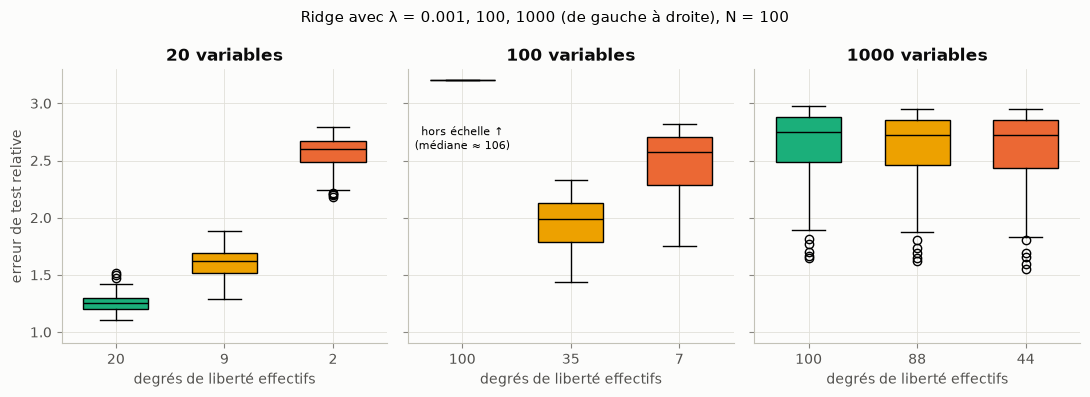

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=True)
ymax = 3.2
for ax, p in zip(axes, ps):
    rel, df, _ = res[p]
    bp = ax.boxplot(np.clip(rel, None, ymax), patch_artist=True, widths=0.6,
                    medianprops=dict(color="k"))
    for patch, c in zip(bp["boxes"], [COLORS[2], COLORS[3], COLORS[1]]):
        patch.set_facecolor(c)
    ax.set_xticks([1, 2, 3], [f"{d:.0f}" for d in df.mean(0)])
    for k in range(3):
        med = np.median(rel[:, k])
        if med > ymax:
            ax.annotate(f"hors échelle ↑\n(médiane ≈ {med:.0f})", (k + 1, 2.6),
                        ha="center", fontsize=8)
    ax.set_title(f"{p} variables")
    ax.set_xlabel("degrés de liberté effectifs")
    ax.set_ylim(0.9, ymax + 0.1)
axes[0].set_ylabel("erreur de test relative")
fig.suptitle("Ridge avec λ = 0.001, 100, 1000 (de gauche à droite), N = 100", fontsize=11)
plt.tight_layout()
plt.show()

**Lecture.**

- $p = 20$ : le moins régularisé (20 ddl, quasi moindres carrés) gagne : on a assez de
  données pour estimer les 20 coefficients avec un faible biais.
- $p = 100 = N$ : avec $\lambda = 0.001$ on **interpole** les données ; la variance
  explose (erreur relative médiane de l'ordre de 100, valeurs écrêtées sur la figure).
  Une régularisation modérée ($\lambda = 100$, $\approx 35$ ddl) est la meilleure.
- $p = 1000$ : aucune méthode ne fait beaucoup mieux que la prédiction nulle, dont
  l'erreur relative vaut $1 + \mathrm{SNR} = 3$ ; les trois valeurs de $\lambda$ donnent
  des erreurs très voisines (λ = 100 et 1000 font un peu mieux que la quasi-interpolation).
  Avec 100 observations on ne peut pas espérer retrouver 1000 coefficients : la seule
  chose qu'on puisse bien estimer est une direction moyenne (ici celle du facteur
  commun de corrélation).

Pour mieux voir l'optimum, traçons l'erreur relative médiane en fonction des degrés
de liberté, pour une grille fine de $\lambda$ (30 répétitions par valeur de $p$).

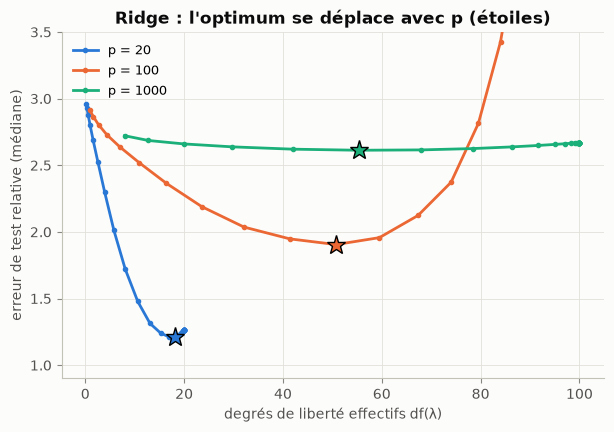

In [4]:
rng = np.random.RandomState(1)
lam_grid = np.logspace(-3, 4, 30)
fig, ax = plt.subplots(figsize=(7, 4.5))
for c, p in zip(COLORS, ps):
    rel, df, _ = simulate_ridge(p, lam_grid, 30, rng)
    med = np.median(rel, 0)
    ax.plot(df.mean(0), med, "o-", color=c, ms=3, label=f"p = {p}")
    k = np.argmin(med)
    ax.plot(df.mean(0)[k], med[k], "*", color=c, ms=14, mec="k")
ax.set_ylim(0.9, 3.5)
ax.set_xlabel("degrés de liberté effectifs df(λ)")
ax.set_ylabel("erreur de test relative (médiane)")
ax.set_title("Ridge : l'optimum se déplace avec p (étoiles)")
ax.legend()
plt.show()

Pour $p = 20$, l'optimum est en bout de courbe (presque pas de régularisation) ; pour
$p = 100$ il se situe vers 50 ddl ; pour $p = 1000$ la courbe est très plate et
l'optimum (vers 50 ddl) est bien en deçà des 100 ddl de l'interpolation.

> **À retenir.** Quand $p \gg N$, la variance domine : les méthodes très
> régularisées (beaucoup de biais, peu de variance) sont souvent les meilleures.
> Le cas $p \approx N$ est particulièrement dangereux pour une méthode sans
> régularisation (interpolation instable).

## 3. Analyse discriminante linéaire diagonale

**Rappel (LDA, section 4.3).** On suppose que, dans la classe $k$,
$X \sim \mathcal N(\mu_k, \Sigma)$ avec une covariance $\Sigma$ commune, et que la
classe $k$ a la probabilité a priori $\pi_k$. La règle de Bayes classe $x$ dans la
classe qui maximise $\log\pi_k + \log\varphi_k(x)$, où $\varphi_k$ est la densité
gaussienne.

Quand $p > N$, l'estimation de $\Sigma$ (matrice $p\times p$, rang $\le N-K$) est
singulière : on ne peut pas l'inverser.

**Hypothèse d'indépendance.** On impose que $\Sigma$ soit **diagonale** :
$\Sigma = \operatorname{diag}(\sigma_1^2,\dots,\sigma_p^2)$. La densité se factorise
alors en produit de densités univariées, et
$$\log\varphi_k(x) = -\frac12\sum_{j=1}^p \frac{(x_j-\mu_{kj})^2}{\sigma_j^2} + \text{(termes ne dépendant pas de } k).$$
En remplaçant $\mu_{kj}$ par la moyenne empirique $\bar x_{kj}$ et $\sigma_j$ par
l'écart-type intra-classe poolé $s_j$, puis en multipliant par 2, on obtient le
**score discriminant** de l'éq. (18.2) du livre :
$$\delta_k(x^*) = -\sum_{j=1}^p \frac{(x^*_j - \bar x_{kj})^2}{s_j^2} + 2\log\pi_k ,$$
et la règle $C(x^*) = \arg\max_k \delta_k(x^*)$ (éq. (18.3)).

> **Intuition.** C'est un classifieur du **centroïde le plus proche**, après avoir
> standardisé chaque variable par son écart-type. On n'estime que $Kp + p$ paramètres
> (centroïdes et variances) au lieu de $Kp + p(p+1)/2$ : avec $p = 6830$ gènes,
> c'est environ $6\cdot 10^4$ contre $2{,}3\cdot 10^7$.
> C'est aussi un cas particulier du **Bayes naïf** (section 6.6.3).

### Les données NCI

Les données NCI60 (déjà vues au chapitre 14) : 6830 gènes mesurés sur 64 lignées
cellulaires cancéreuses. Le livre illustre la section 18.2 sur d'autres données
(SRBCT, 4 classes) non disponibles ici ; nous reproduisons la même analyse sur NCI.

Certaines classes n'ont qu'un ou deux échantillons (« K562A-repro », « UNKNOWN »,
« PROSTATE »…) : nous ne gardons que les **8 types de cancer ayant au moins 5
échantillons**, soit $N = 57$ et $K = 8$.

In [5]:
X_all, lab_all = datasets.load_nci()
types, counts = np.unique(lab_all, return_counts=True)
keep = np.isin(lab_all, types[counts >= 5])
X, lab = X_all[keep], lab_all[keep]
classes = np.unique(lab)
print("X :", X.shape)
for c in classes:
    print(f"  {c:9s} {np.sum(lab == c)} échantillons")

X : (57, 6830)
  BREAST    7 échantillons
  CNS       5 échantillons
  COLON     7 échantillons
  LEUKEMIA  6 échantillons
  MELANOMA  8 échantillons
  NSCLC     9 échantillons
  OVARIAN   6 échantillons
  RENAL     9 échantillons


On sépare (de façon stratifiée) un tiers des échantillons comme **échantillon test**,
le reste servant à l'apprentissage et à la validation croisée.